# 实验3：多目标与强化学习派单（完成版）

课件首页写“实验二—任务分配(2)”，作业细则和Notebook写实验3，保留来源差异。Part A对应原Cells5—25；Part B TODO对应Cells31/33。原始输入未覆盖。生产实现集中在`evolution.py`、`rl_dispatch.py`及数据入口；这里从干净Kernel实际运行核心参考实验，并重算正式汇总。

签到→相邻签到代理→采样模拟日→训练回合→测试模拟日五种身份分别说明。默认种群100/300代/5seed，RL默认300回合，不以缩小参数冒充教师实验。完整控制变量、加分与复验结果另由脚本和固定run索引追溯。

In [1]:
from pathlib import Path
import sys, os, json
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['OMP_NUM_THREADS']='1'
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'task2/src/online.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
if str(ROOT/'task2/src') not in sys.path:sys.path.insert(0,str(ROOT/'task2/src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from task2.scripts.build_figures import P, COLORS
from matplotlib.colors import LinearSegmentedColormap
VALUE_CMAP=LinearSegmentedColormap.from_list('p2value',[P['Paper'],P['P1'],P['C1'],P['Ink']])
get_ipython().run_line_magic('matplotlib','inline')
np.set_printoptions(precision=4,suppress=True)

## A.1 数据、共同可行图与评价

前70%日期用于训练，最后30%为测试；训练内后20%为验证。司机热点只从相应训练部分取得。局部坐标为教学近似km，source_crs未获独立证明。候选为3km曼哈顿半径内最近6司机。HV使用实例预先确定的统一界和reference1.1；Spacing先容差去重、非支配筛选。

In [2]:
from task2.src.dispatch_data import load_data
from task2.src.evolution import (DispatchProblem,DTLZ2,make_batch,run_nsga,weighted_km,km_initial_genes,
    knee_point,constraint_choice,das_dennis)
from front_metrics import canonical_front as unique_front, evaluate_front
def hypervolume(F,ideal,nadir):return evaluate_front(F,ideal,nadir)['HV']
def spacing(F,ideal,nadir):return evaluate_front(F,ideal,nadir)['Spacing_cv']
bundle=load_data();display(pd.DataFrame(bundle.audit['split']).T)
batch=make_batch(bundle.trips_train_inner,bundle.checkins_train_inner,hour=18,seed=2024)
problem=DispatchProblem(batch);ideal,nadir=problem.normalization()
lambdas=np.r_[0.,np.geomspace(.05,60.,40)]
km=weighted_km(problem,lambdas);kmF=unique_front(np.asarray([r['F'] for r in km]))
print('KM HV',hypervolume(kmF,ideal,nadir),'Spacing',spacing(kmF,ideal,nadir))

,rows,dates,start,end
trips_train_inner,19617,139,2012-04-03,2012-10-18
trips_validation,1972,35,2012-10-19,2012-11-26
trips_train,21589,174,2012-04-03,2012-11-26
trips_test,3961,75,2012-11-27,2013-02-15


KM HV 1.098976782681488 Spacing 0.6622301729442006


## A.2 NSGA-II/III与五seed收敛

遗传解码冲突修复保持同一候选图。保存五个seed的全部前沿；区间为seed标准差，不能只报告最好一次。

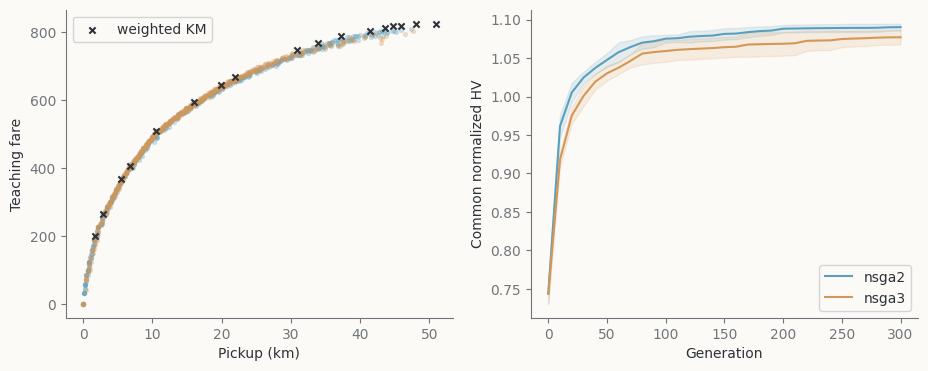

,algorithm,seed,HV,Spacing,n_eval,seconds
0,nsga2,0,1.088061,0.540638,30100,1.613418
1,nsga2,1,1.086845,0.544685,30100,1.705944
2,nsga2,2,1.091366,0.497134,30100,1.762499
3,nsga2,3,1.087373,0.447925,30100,1.930842
4,nsga2,4,1.097576,0.496436,30100,1.792937
5,nsga3,0,1.084189,0.724932,30100,2.329964
6,nsga3,1,1.072383,1.080883,30100,2.392526
7,nsga3,2,1.090092,1.001173,30100,2.494671
8,nsga3,3,1.070686,0.922802,30100,2.445610
9,nsga3,4,1.068108,0.961463,30100,2.388691


In [3]:
runs={algo:[run_nsga(problem,algo=algo,pop_size=100,n_gen=300,seed=s) for s in range(5)]
      for algo in ['nsga2','nsga3']}
fig,axs=plt.subplots(1,2,figsize=(11,4))
for c,(algo,rs) in zip(COLORS,runs.items()):
    for r in rs:axs[0].scatter(r['F'][:,1],-r['F'][:,0],s=8,color=c,alpha=.25)
    histories=np.array([[hypervolume(h['F'],ideal,nadir) for h in r['history']] for r in rs])
    x=[h['generation'] for h in rs[0]['history']]
    axs[1].plot(x,histories.mean(0),color=c,label=algo)
    axs[1].fill_between(x,histories.mean(0)-histories.std(0,ddof=1),histories.mean(0)+histories.std(0,ddof=1),color=c,alpha=.15)
axs[0].scatter(kmF[:,1],-kmF[:,0],marker='x',color=P['Ink'],s=20,label='weighted KM')
axs[0].set(xlabel='Pickup (km)',ylabel='Teaching fare');axs[0].legend()
axs[1].set(xlabel='Generation',ylabel='Common normalized HV');axs[1].legend();plt.show()
display(pd.DataFrame([dict(algorithm=a,seed=s,HV=hypervolume(r['F'],ideal,nadir),Spacing=spacing(r['F'],ideal,nadir),n_eval=r['n_eval'],seconds=r['runtime']) for a,rs in runs.items() for s,r in enumerate(rs)]))

## A.3 三目标与DTLZ2

第三目标是服务数；三目标105种群/105方向（原Cell19），不同于双目标100种群。DTLZ2是已知球面前沿的独立数学对照，不能用派单front形状替代。

In [4]:
p3=DispatchProblem(batch,n_obj=3);i3,n3=p3.normalization()
rows=[]
for a in ['nsga2','nsga3']:
    for s in range(5):
        r=run_nsga(p3,algo=a,pop_size=105,n_gen=300,seed=s,ref_dirs=das_dennis(3,13))
        rows.append(dict(problem='dispatch3',algorithm=a,seed=s,HV=hypervolume(r['F'],i3,n3),Spacing=spacing(r['F'],i3,n3)))
        r=run_nsga(DTLZ2(),algo=a,pop_size=92,n_gen=400,seed=s,ref_dirs=das_dennis(3,12))
        rows.append(dict(problem='DTLZ2',algorithm=a,seed=s,HV=hypervolume(r['F'],np.zeros(3),np.ones(3)),Spacing=spacing(r['F'],np.zeros(3),np.ones(3)),front_error=np.abs(np.linalg.norm(r['F'],axis=1)-1).mean()))
display(pd.DataFrame(rows))

,problem,algorithm,seed,HV,Spacing,front_error
0,dispatch3,nsga2,0,1.001723,0.616248,NaN
1,DTLZ2,nsga2,0,0.712676,0.449043,0.006086
2,dispatch3,nsga2,1,1.024877,0.609882,NaN
3,DTLZ2,nsga2,1,0.713890,0.503566,0.007447
4,dispatch3,nsga2,2,1.006111,0.689902,NaN
5,DTLZ2,nsga2,2,0.703688,0.551150,0.006688
6,dispatch3,nsga2,3,1.019739,0.550825,NaN
7,DTLZ2,nsga2,3,0.706174,0.433256,0.008456
8,dispatch3,nsga2,4,1.021775,0.637361,NaN
9,DTLZ2,nsga2,4,0.699127,0.464975,0.009555


## A.4 时段、单项增强与折中选择

完整5seed的8/13/18/23时段、种群/代数单项、KM初始化和经验证组合在实际run中保存。下面重算该表的当前规范指标并查看，不将读取旧run冒充新进化实验。膝点与接驾预算60km是不同偏好，不能无依据称某个业务最优。

In [5]:
summary_path=ROOT/'task2/results/evolution/summary.csv'
if not summary_path.exists():raise FileNotFoundError('Run staged evolution scripts described in the reproducibility guide first')
display(pd.read_csv(summary_path).groupby(['stage','algorithm','n_obj','pop_size','n_gen'],dropna=False)[['HV','Spacing_cv','total_objective_evals','total_runtime']].agg(['mean','std']))
front=unique_front(runs['nsga2'][0]['F'])
k=knee_point(front);c=constraint_choice(front,60.)
display(pd.DataFrame([dict(rule='knee',F=front[k]),dict(rule='pickup<=60km',F=front[c] if c is not None else None)]))
initial=km_initial_genes(problem,lambdas)
assert all(problem.decode(g)==problem.decode(problem.encode_pairs(problem.decode(g))) for g in initial)
print('KM初始基因真实编码验证',len(initial))

HV            \
                                                           mean       std   
stage                algorithm   n_obj pop_size n_gen                       
baseline             nsga2       2     100.0    300.0  1.056491  0.026173   
                                 3     92.0     400.0  0.707111  0.006190   
                                       105.0    300.0  1.014845  0.010260   
                     nsga3       2     100.0    300.0  1.038305  0.028140   
                                 3     92.0     400.0  0.744325  0.000235   
                                       105.0    300.0  1.012638  0.005689   
basic                nsga2       2     100.0    300.0  1.179926  0.000070   
combination          nsga2       2     200.0    300.0  1.112912  0.000072   
                     nsga3       2     200.0    300.0  1.112072  0.000085   
confirmation_km      nsga2       2     100.0    300.0  1.090298  0.012225   
confirmation_teacher nsga2       2     100.0    300.0  1.058828  0.011898   
hybrid               nsga2       2     100.0    300.0  1.111427  0.000291   
                     nsga3       2     100.0    300.0  1.111494  0.000169   
scale                nsga2       2     100.0    600.0  1.094778  0.006998   
                                       200.0    300.0  1.101432  0.004523   
                     nsga3       2     100.0    600.0  1.090552  0.006213   
                                       200.0    300.0  1.085327  0.006452   
weighted_km          weighted_km 2     NaN      NaN    1.073163  0.020885   
                                 3     NaN      NaN    1.023454       NaN   

                                                      Spacing_cv            \
                                                            mean       std   
stage                algorithm   n_obj pop_size n_gen                        
baseline             nsga2       2     100.0    300.0   0.452070  0.048508   
                                 3     92.0     400.0   0.480398  0.047397   
                                       105.0    300.0   0.620843  0.050214   
                     nsga3       2     100.0    300.0   0.778170  0.161454   
                                 3     92.0     400.0   0.296525  0.006643   
                                       105.0    300.0   0.688450  0.014117   
basic                nsga2       2     100.0    300.0   0.558998  0.029949   
combination          nsga2       2     200.0    300.0   0.626300  0.013491   
                     nsga3       2     200.0    300.0   1.228595  0.178787   
confirmation_km      nsga2       2     100.0    300.0   0.430119  0.028225   
confirmation_teacher nsga2       2     100.0    300.0   0.452040  0.033880   
hybrid               nsga2       2     100.0    300.0   0.470140  0.037229   
                     nsga3       2     100.0    300.0   0.901161  0.094288   
scale                nsga2       2     100.0    600.0   0.501365  0.057033   
                                       200.0    300.0   0.617271  0.026914   
                     nsga3       2     100.0    600.0   0.931240  0.118579   
                                       200.0    300.0   1.179619  0.196272   
weighted_km          weighted_km 2     NaN      NaN     0.864461  0.188567   
                                 3     NaN      NaN     0.714441       NaN   

                                                      total_objective_evals  \
                                                                       mean   
stage                algorithm   n_obj pop_size n_gen                         
baseline             nsga2       2     100.0    300.0               30100.0   
                                 3     92.0     400.0               36892.0   
                                       105.0    300.0               31605.0   
                     nsga3       2     100.0    300.0               30100.0   
                                 3     92.0     400.0               36892.0   
                 

,rule,F
0,knee,"[-516.416158925, 11.3502856731]"
1,pickup<=60km,"[-802.6878290994, 44.6186842484]"


KM初始基因真实编码验证 10


## B.1 Q-learning TODO1—3与教师原测试

Q更新只在后继真正可行动作与WAIT上取max；动作持续delta片就折扣delta次；终止状态不bootstrap。以下原始断言逐字保留，只把函数来源换成已完成模块。

In [6]:
from task2.src.rl_dispatch import (DEFAULT,Config,QTable,DoubleQTable,q_update,double_q_update,
    region_long_term_value,make_q_km,run_episode,sample_episode,train_q_km,
    greedy_nearest,km_fare,make_repositioner,T,N_ZONES,WAIT,GAMMA,DELTA)
# 单元测试：手算验证
_qt = QTable()
_qt.Q[5, 3, 7], _qt.Q[5, 3, 9], _qt.Q[5, 3, WAIT] = 30.0, 99.0, 10.0
td = q_update(_qt, 2, 0, 3, 20.0, 5, 3, np.array([7]))
assert abs(td - (20 + GAMMA ** 3 * 30)) < 1e-9, "max 只能在 avail ∪ {WAIT} 上取：应为 30，而不是 99"
assert _qt.N[2, 0, 3] == 1 and abs(_qt.Q[2, 0, 3] - (20 + GAMMA ** 3 * 30)) < 1e-9, "首次访问 alpha=1"
assert abs(_qt.V[5, 3] - 30) < 1e-9, "V(s') 应更新为样本 m 的平均"
q_update(_qt, 2, 0, 3, 0.0, 5, 3, np.array([], int))      # 无订单可接：m = Q[WAIT] = 10
assert abs(_qt.Q[2, 0, 3] - (20 + GAMMA ** 3 * 30 + GAMMA ** 3 * 10) / 2) < 1e-9, "第二次 alpha=1/2"
assert abs(_qt.V[5, 3] - 20) < 1e-9
assert abs(q_update(_qt, T - 1, 0, WAIT, 7.0, T + 2, 1, np.array([5])) - 7.0) < 1e-9, "终止状态只有 r"
print("TODO 1 通过测试 ✓")

TODO 1 通过测试 ✓


In [7]:
# 单元测试
_V = np.zeros((T + 1, N_ZONES))
_V[:T, 0], _V[:T, 1] = 5.0, 50.0                          # V[T] 保持 0（一天结束）
_LT = region_long_term_value(_V)
assert _LT.shape == (T, N_ZONES, N_ZONES)
assert abs(_LT[10, 0, 1] - (GAMMA ** DELTA[0, 1] * 50 - GAMMA * 5)) < 1e-9
assert abs(_LT[T - 1, 1, 0] - (GAMMA ** DELTA[1, 0] * 0 - GAMMA * 0)) < 1e-9, "越过一天结束时应取 V[T] = 0"
assert abs(_LT[10, 1, 2] - (0 - GAMMA * 50)) < 1e-9
_ctx = dict(t=10, fare=np.array([10.0, 10.0]), drv_zone=np.array([0, 1]),
            dest_zone=np.array([1, 2]), feas=np.array([[True, True], [True, True]]))
_pairs = sorted((int(a), int(b)) for a, b in make_q_km(_LT)(_ctx))
# 司机 1 在高价值区域 1：接去区域 2 的单 w=10-γ·50<0 不派；区域 0 的司机接去区域 1 的单收益最大
assert _pairs == [(0, 0)], f"期望只派 (司机0, 订单0)，实际 {_pairs}"
print("TODO 2 / TODO 3 通过测试 ✓")

TODO 2 / TODO 3 通过测试 ✓


## B.2 真实300回合训练、学习曲线与TD

每回合采样1500代理订单构成一个模拟日。这里从inner训练，validation只用于观察；它不是300个真实运营日。初始司机来自inner签到。

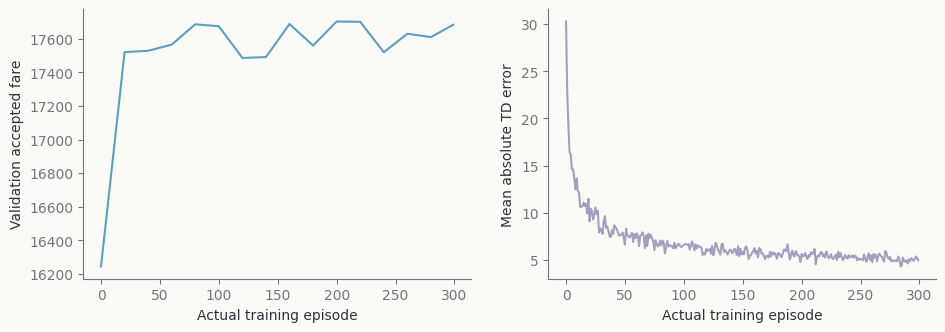

300 real simulated episodes, seconds= 34.2165781409999


In [8]:
qt,curve,td,episode_log,seconds=train_q_km(bundle.trips_train_inner,bundle.checkins_train_inner,60,
    n_episodes=300,seed=2024,validation_pool=bundle.trips_validation)
assert len(td)==300
fig,axs=plt.subplots(1,2,figsize=(11,3.5))
axs[0].plot(curve[:,0],curve[:,1],color=COLORS[0]);axs[0].set(xlabel='Actual training episode',ylabel='Validation accepted fare')
axs[1].plot(np.arange(300),td,color=COLORS[3],alpha=.7);axs[1].set(xlabel='Actual training episode',ylabel='Mean absolute TD error');plt.show()
print('300 real simulated episodes, seconds=',seconds)

## B.3 区域价值与beta验证

LT区域中心近似只用于价值估计，真实派单的忙时来自实际接驾+送客距离。beta曲线在验证分区计算；最终测试不参与选择。收入按教师定义在接单时确认，另记录horizon内完成与未完成服务。

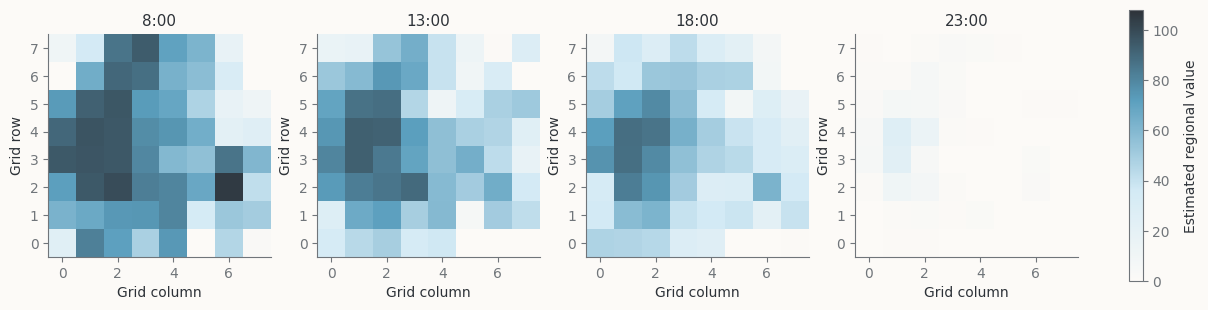

,revenue,answer_rate,avg_pickup,nonpositive_fraction
beta,,,,
0.0,15728.160837,0.515200,1.891222,0.000000
0.2,16132.852592,0.532267,1.908406,0.000457
0.4,16508.878851,0.561200,1.905602,0.011389
0.5,16768.283025,0.584267,1.897099,0.033443
0.6,16896.798876,0.612133,1.925254,0.080980
0.8,16056.270702,0.613467,1.915416,0.214231
1.0,13955.642463,0.564133,1.920395,0.382524


In [9]:
fig,axs=plt.subplots(1,4,figsize=(12,3),layout='constrained')
for ax,h in zip(axs,[8,13,18,23]):
    t=(h*60-360)//10
    im=ax.imshow(qt.V[t].reshape(8,8),origin='lower',vmin=0,vmax=qt.V.max(),cmap=VALUE_CMAP);ax.set_title(f'{h}:00');ax.set(xlabel='Grid column',ylabel='Grid row')
fig.colorbar(im,ax=axs,label='Estimated regional value');plt.show()
LT=region_long_term_value(qt.V);rows=[]
for seed in range(50000,50005):
    ep=sample_episode(bundle.trips_validation,60,seed,bundle.checkins_train_inner)
    for beta in [0,.2,.4,.5,.6,.8,1]:
        m,_=run_episode(ep,make_q_km(LT,beta));rows.append(dict(day_seed=seed,beta=beta,**m))
display(pd.DataFrame(rows).groupby('beta')[['revenue','answer_rate','avg_pickup','nonpositive_fraction']].mean())

## B.4 40/60/100车、参数、Double、主动调度与NSGA融合

正式实验包含每车队300回合、gamma/grid/patience单因素、Double在beta1的五训练seed、计入空驶的相邻调度、NSGA前沿与实际模拟效果。表中每行来自可追溯day_metrics，不是教师PPT参考数值。需要重训全套时执行复现指南的分阶段脚本；不将加载表格声称为此Kernel再次训练。

Q/Double共用行为流但有独立更新coin；Double缓解统计高估不保证消除共享订单竞争。调度收入与空驶成本分开报告，不能忽略空驶而宣称净收益。融合的估计长期目标与真实模拟收入分别展示。

In [10]:
rl_root=ROOT/'task2/results/rl'
active_index=json.loads((rl_root/'ACTIVE_RUNS.json').read_text())
paths=[ROOT/'task2'/p for p in active_index['active_day_metrics']]
tables=[]
for p in paths:
    # The explicit active index excludes invalid and historical equivalent evaluations.
    raw=json.loads(p.read_text())
    if isinstance(raw,list) and raw:
        t0=pd.DataFrame(raw);t0['run']=str(p.parent.relative_to(rl_root));tables.append(t0)
if not tables:raise FileNotFoundError('Run RL experiments first; see reproducibility guide')
all_days=pd.concat(tables,ignore_index=True)
display(all_days.groupby(['run','policy'])[['revenue','answer_rate','avg_pickup','empty_km']].mean())
print('每行统计单位：一个明确run中的模拟日；不同训练seed/分区不合并为独立真实运营日。')

revenue  answer_rate  \
run                                        policy                               
beta_validation_v1                         beta0    15892.177152     0.522267   
                                           beta0.2  16204.278203     0.532000   
                                           beta0.4  16429.219337     0.556133   
                                           beta0.5  16830.682351     0.590000   
                                           beta0.6  16806.976606     0.607867   
...                                                          ...          ...   
sensitivity_v2_rngfix/patience1_validation km       15357.847569     0.507067   
                                           qkm      16366.488756     0.574667   
sensitivity_v2_rngfix/patience3_validation greedy   17099.146833     0.627467   
                                           km       16203.982236     0.530533   
                                           qkm      17290.172340     0.606400   

                                                    avg_pickup  empty_km  
run                                        policy                         
beta_validation_v1                         beta0      1.891842       0.0  
                                           beta0.2    1.897665       0.0  
                                           beta0.4    1.890172       0.0  
                                           beta0.5    1.890889       0.0  
                                           beta0.6    1.917231       0.0  
...                                                        ...       ...  
sensitivity_v2_rngfix/patience1_validation km         1.881215       0.0  
                                           qkm        1.879529       0.0  
sensitivity_v2_rngfix/patience3_validation greedy     1.563377       0.0  
                                           km         1.896895       0.0  
                                           qkm        1.889590       0.0  

[132 rows x 4 columns]

每行统计单位：一个明确run中的模拟日；不同训练seed/分区不合并为独立真实运营日。


思考题的实测解释、负结果和边界见Experiment Report及要求矩阵。完整基线/单项/父项/融合/移除/独立测试在run索引中单列。这里的原TODO断言与真实300回合已从干净Kernel执行；报告和图重建入口与实验重算入口分别提供。